# Assignment 3: Advanced, Multivariate, Temporal and Spatial Visualisation

**CSC 6732 Data Visualisation, University of Zambia (MSc Data Science)**

Dataset: World Bank World Development Indicators extract used in Assignment 1. It covers
9 Southern African countries × 25 years (2000–2024) = 225 country-years: electricity access,
renewable energy share, GDP per capita, urbanisation, life expectancy and population.

The notebook follows the five tasks of the brief:
1. **Multivariate analysis**: questions involving three or more variables
2. **Temporal analysis**: trend, short-term variation, seasonality, structural change, anomalies, moving averages
3. **Geospatial analysis**: rates versus counts on maps
4. **Alternative representations**: the same question shown two ways
5. **Evidence-based findings**: observations separated from interpretations

It closes with the methodological limitations. Every figure is also saved to `figures/` for the report.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import Image, display

from src import analysis, data, style

warnings.filterwarnings("ignore", category=FutureWarning)
style.apply()
pd.set_option("display.precision", 2)

df = data.load()
YEAR_MIN, YEAR_MAX = int(df["year"].min()), int(df["year"].max())
NAMES = df.drop_duplicates("iso3").set_index("iso3")["country"]
print(f"{len(df)} country-years, {df['iso3'].nunique()} countries, {YEAR_MIN}-{YEAR_MAX}")
df.head()

225 country-years, 9 countries, 2000-2024


,country,iso2,iso3,income,capital,lon,lat,year,access,renewables,...,pop_with,pop_without_m,log_gdp_pc,yoy_change,access_ma,pop_without_m_ma,anomaly,rank,gap_to_leader,required_pp_2030
0,Angola,AO,AGO,Lower middle income,Luanda,13.24,-8.81,2000,24.2,73.8,...,3.92e+06,12.28,2.75,NaN,NaN,NaN,False,5,48.2,2.53
1,Angola,AO,AGO,Lower middle income,Luanda,13.24,-8.81,2001,20.0,72.8,...,3.35e+06,13.40,2.73,-4.2,NaN,NaN,True,6,50.2,2.76
2,Angola,AO,AGO,Lower middle income,Luanda,13.24,-8.81,2002,26.3,70.8,...,4.56e+06,12.77,3.00,6.3,23.50,12.81,False,5,50.4,2.63
3,Angola,AO,AGO,Lower middle income,Luanda,13.24,-8.81,2003,27.4,65.6,...,4.92e+06,13.03,3.05,1.1,24.57,13.07,False,5,51.4,2.69
4,Angola,AO,AGO,Lower middle income,Luanda,13.24,-8.81,2004,28.4,62.3,...,5.28e+06,13.32,3.16,1.0,27.37,13.04,False,5,52.2,2.75


Cleaning follows the Assignment 1 audit:
- Namibia's ISO2 code `"NA"` is read as text, and ISO3 is the key.
- `Region` (constant) and `Period start` (duplicates `Year`) are dropped.
- Renewables are left missing for 2022–2024 and never imputed.

Derived variables used below:
- people without electricity = population × (1 − access/100)
- log₁₀ GDP per capita
- year-on-year change in access
- trailing moving averages

## Task 1: Multivariate analysis

**Question 1.1: Is electricity access associated with wealth, urbanisation, health and the energy mix, and at what level does the association hold: between countries, within a country over time, or year to year?**

A single pooled correlation matrix answers this badly. The 225 rows mix two sources of variation, so the
matrix is computed four ways:

| View | Data | What it asks |
|---|---|---|
| Pooled | all country-years | the usual (ambiguous) correlation |
| Between | 9 country means | do richer / more urban *countries* have more access? |
| Within | country-demeaned values | when *a country* grows richer, does its access rise? (still shares the common time trend) |
| Changes | year-on-year changes, centred per country | in years when GDP grows faster than usual, does access also grow faster than usual? |

Spearman rank correlation is used because GDP and population are heavily skewed. GDP is log-transformed.
The extra variables matter analytically. Urbanisation is the cheapest route to grid access (density),
GDP proxies the ability to pay for infrastructure, and life expectancy is the development outcome
electricity is meant to support. The renewables share is the energy-mix question.

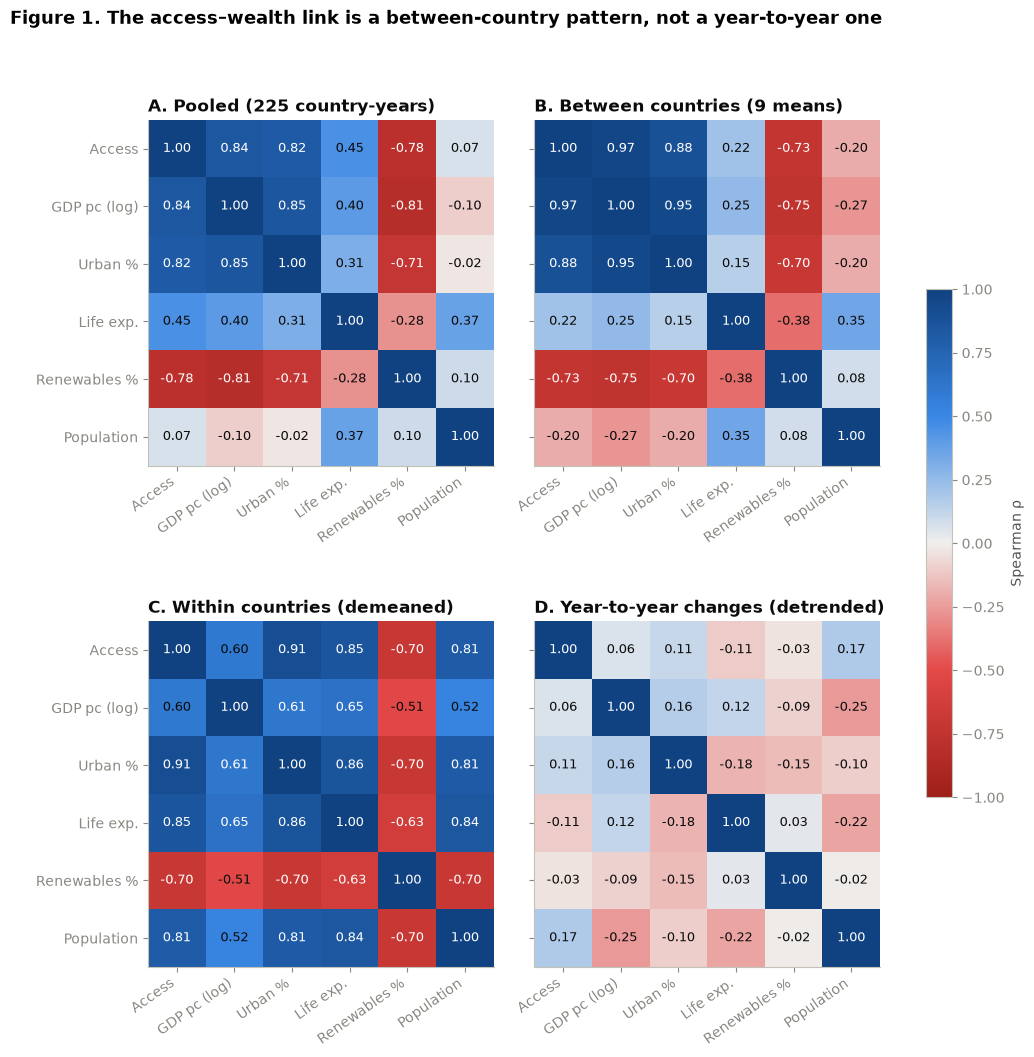

,pooled,between,within,changes
GDP pc (log),0.84,0.97,0.60,0.06
Urban %,0.82,0.88,0.91,0.11
Life exp.,0.45,0.22,0.85,-0.11
Renewables %,-0.78,-0.73,-0.70,-0.03


In [2]:
mats = analysis.correlation_matrices(df)
labels = ["Access", "GDP pc (log)", "Urban %", "Life exp.", "Renewables %", "Population"]
titles = {
    "pooled": "A. Pooled (225 country-years)",
    "between": "B. Between countries (9 means)",
    "within": "C. Within countries (demeaned)",
    "changes": "D. Year-to-year changes (detrended)",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 11), gridspec_kw=dict(hspace=0.45, wspace=0.08))
for n, (ax, (key, title)) in enumerate(zip(axes.flat, titles.items())):
    m = mats[key].to_numpy()
    im = ax.imshow(m, cmap=style.DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(6), labels, rotation=35, ha="right")
    ax.set_yticks(range(6), labels if n % 2 == 0 else [""] * 6)
    ax.grid(False)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(m[i, j]) > 0.6 else style.INK)
    ax.set_title(title)
fig.colorbar(im, ax=axes, shrink=0.6, label="Spearman ρ")
fig.suptitle("Figure 1. The access–wealth link is a between-country pattern, not a year-to-year one",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
style.save(fig, "fig01_correlation_views")
plt.show()

summary_corr = pd.DataFrame({k: [mats[k].loc["access", c] for c in ["gdp_pc", "urban", "life_exp", "renewables"]]
                             for k in mats}, index=["GDP pc (log)", "Urban %", "Life exp.", "Renewables %"])
summary_corr

**Reading Figure 1.**
- **Pooled and between:** access rises with log GDP (ρ = 0.84 pooled, **0.97** between countries) and with
  urbanisation (0.82 / 0.88).
- **Within countries:** the GDP link drops to 0.60. Almost everything correlates with almost everything
  (access–population 0.81), because every series trends upward over time.
- **Year-to-year changes:** once each country's own trend is removed, the associations collapse to roughly
  zero (access–GDP 0.06). Years of faster-than-usual GDP growth are **not** years of faster-than-usual
  electrification.

So the "electricity follows wealth" story is about long-run *levels* across countries, not short-run
co-movement. The renewables share is **negatively** associated with access (−0.78 pooled). This is a
warning, not a paradox: WDI's renewable share includes traditional biomass (firewood, charcoal), so a high
share mostly signals poverty, not clean electricity.

**Question 1.2: Does the wealth–access relationship depend on urbanisation and population size, and has it shifted between 2000 and 2024?**

A bubble plot encodes four variables at once: GDP (x, log), access (y), urbanisation (colour, sequential)
and population (bubble area). Two facets add time.

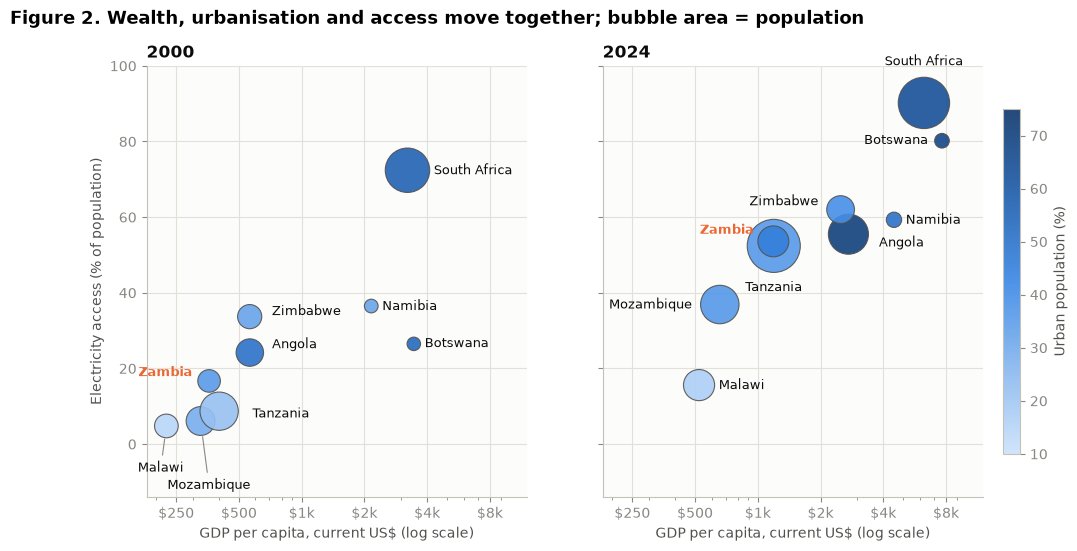

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharey=True)
pmax = df["population"].max()
# manual label offsets (points) where neighbouring bubbles would collide; default = right of the bubble
LABEL_POS = {
    (2000, "ZMB"): (-12, 6, "right"), (2000, "TZA"): (24, -2, "left"), (2000, "MOZ"): (6, -46, "center", True),
    (2000, "MWI"): (-4, -30, "center", True), (2000, "AGO"): (16, 6, "left"), (2000, "ZWE"): (16, 4, "left"),
    (2024, "ZMB"): (-14, 8, "right"), (2024, "TZA"): (0, -30, "center"), (2024, "MOZ"): (-20, 0, "right"),
    (2024, "ZWE"): (-16, 6, "right"), (2024, "AGO"): (22, -6, "left"), (2024, "BWA"): (-10, 0, "right"),
    (2024, "ZAF"): (0, 30, "center"),
}
for ax, yr in zip(axes, [YEAR_MIN, YEAR_MAX]):
    d = df[df["year"] == yr]
    sc = ax.scatter(d["gdp_pc"], d["access"], s=60 + 1400 * d["population"] / pmax, c=d["urban"],
                    cmap=style.BLUES, vmin=10, vmax=75, edgecolor=style.INK_2, linewidth=0.8, alpha=0.9, zorder=3)
    for _, r in d.iterrows():
        rad = (60 + 1400 * r["population"] / pmax) ** 0.5 / 2 + 3  # marker radius in points
        dx, dy, ha, *leader = LABEL_POS.get((yr, r["iso3"]), (rad, 0, "left"))
        ax.annotate(r["country"], (r["gdp_pc"], r["access"]), xytext=(dx, dy), textcoords="offset points",
                    ha=ha, va="center", fontsize=9,
                    arrowprops=dict(arrowstyle="-", color=style.MUTED, lw=0.8, shrinkB=rad - 2) if leader else None,
                    color=style.FOCUS if r["iso3"] == "ZMB" else style.INK, fontweight="bold" if r["iso3"] == "ZMB" else None)
    ax.set_xscale("log")
    ax.set_xticks([250, 500, 1000, 2000, 4000, 8000], ["$250", "$500", "$1k", "$2k", "$4k", "$8k"])
    ax.set_xlim(180, 12000)
    ax.set_ylim(-14, 100)
    ax.set_yticks(range(0, 101, 20))
    ax.set_title(f"{yr}")
    ax.set_xlabel("GDP per capita, current US$ (log scale)")
axes[0].set_ylabel("Electricity access (% of population)")
cb = fig.colorbar(sc, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("Urban population (%)")
fig.suptitle("Figure 2. Wealth, urbanisation and access move together; bubble area = population",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
style.save(fig, "fig02_bubble_wealth_access_urban")
plt.show()

**Reading Figure 2.** In both years the darker (more urban) bubbles sit top-right. Over 24 years the whole
cloud moves up more than it moves right:
- Several countries gained 30–45 points of access while their current-US$ GDP per capita barely changed
  (Zambia, Tanzania, Mozambique).
- At the same GDP (about $1,200 in 2024), Zambia and Tanzania sit at the same access level, as in
  Assignment 4.

The large pale bubbles at the bottom left (Tanzania 2000, Mozambique, Malawi) combine low access with low
urbanisation and large populations. That is where most people without electricity live (Task 3).

**Question 1.3: How do the nine countries compare on all development dimensions at once?** A parallel-coordinates
plot for 2021, the last year with complete renewables data. Each axis is rescaled from the minimum to the
maximum across the nine countries. Zambia is highlighted against two benchmarks: Tanzania (same income)
and South Africa (regional leader).

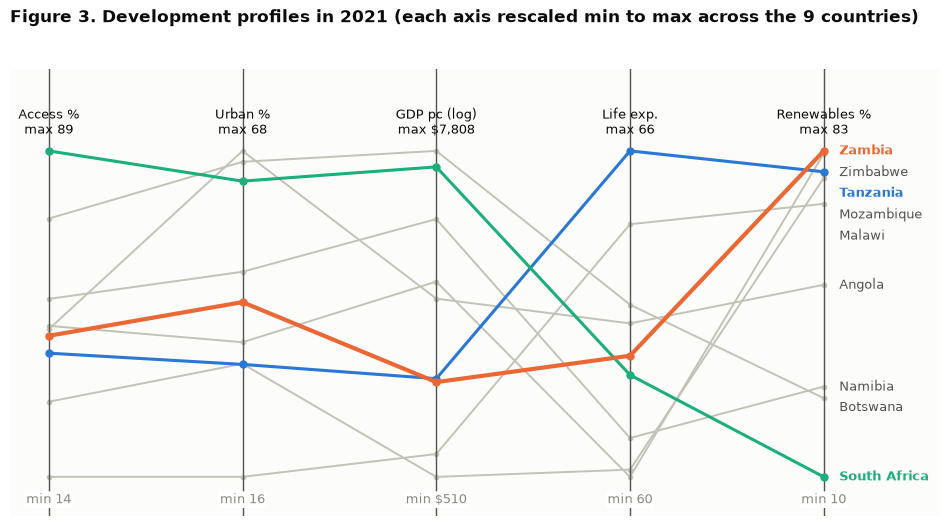

In [4]:
d21 = df[df["year"] == 2021].set_index("iso3")
axes_vars = [("access", "Access %"), ("urban", "Urban %"), ("log_gdp_pc", "GDP pc (log)"),
             ("life_exp", "Life exp."), ("renewables", "Renewables %")]
norm = pd.DataFrame({v: (d21[v] - d21[v].min()) / (d21[v].max() - d21[v].min()) for v, _ in axes_vars})
colors = {"ZMB": style.FOCUS, "TZA": style.BLUE, "ZAF": style.AQUA}
end_labels = []
fig, ax = plt.subplots(figsize=(12, 5.8))
xs = np.arange(len(axes_vars))
for iso in sorted(norm.index, key=lambda i: i in colors):
    c = colors.get(iso, style.GREY)
    ax.plot(xs, norm.loc[iso], color=c, lw=3 if iso == "ZMB" else (2.2 if iso in colors else 1.4), zorder=3 if iso in colors else 2,
            marker="o", ms=5 if iso in colors else 3)
    end_labels.append([norm.loc[iso].iloc[-1], NAMES[iso], c if iso in colors else style.INK_2, iso in colors])
end_labels.sort(key=lambda l: -l[0])  # push right-end labels apart (downwards) so none overlap
for i in range(1, len(end_labels)):
    end_labels[i][0] = min(end_labels[i][0], end_labels[i - 1][0] - 0.065)
for y, name, c, bold in end_labels:
    ax.text(xs[-1] + 0.08, y, name, va="center", fontsize=9, color=c, fontweight="bold" if bold else None)
for x, (v, lab) in zip(xs, axes_vars):
    ax.axvline(x, color=style.INK_2, lw=1)
    lo, hi = d21[v].min(), d21[v].max()
    fmt = (lambda z: f"${10**z:,.0f}") if v == "log_gdp_pc" else (lambda z: f"{z:.0f}")
    ax.text(x, 1.04, f"{lab}\nmax {fmt(hi)}", ha="center", va="bottom", fontsize=9, color=style.INK)
    ax.text(x, -0.05, f"min {fmt(lo)}", ha="center", va="top", fontsize=9, color=style.MUTED,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
ax.set_xticks([])
ax.spines[:].set_visible(False)
ax.set_yticks([])
ax.set_ylim(-0.12, 1.25)
ax.set_xlim(-0.2, len(axes_vars) - 0.4)
ax.grid(False)
ax.set_title("Figure 3. Development profiles in 2021 (each axis rescaled min to max across the 9 countries)", pad=34)
style.save(fig, "fig03_parallel_coordinates_2021")
plt.show()

**Reading Figure 3.** South Africa's line is the mirror image of the low-access group: high on access,
urbanisation and GDP, lowest on renewables (a coal-based system). Zambia and Tanzania follow almost the
same path across access, urbanisation and GDP, and both have very high renewables shares. For Zambia this
is largely hydropower plus biomass, which is why the drought-driven hydro shortfalls of recent years
matter so much. Life expectancy does not separate the groups (the lines cross), which matches its weak
correlations in Figure 1.

## Task 2: Temporal analysis

The brief asks for long-term trend, short-term variation, seasonality, structural change and anomalies.

**Seasonality cannot be studied with this dataset.** The data are annual, one value per country per year,
so there is no within-year cycle to observe. Any seasonal pattern in electricity (for example the
dry-season hydro deficit in Zambia and Zimbabwe) is invisible at this resolution. Studying it would need a
monthly series such as utility generation or load-shedding hours.

### 2.1 Raw versus smoothed series

The moving average is computed as specified:  MAₜ = (1/k) Σᵢ₌₀ᵏ⁻¹ xₜ₋ᵢ, with k = 3 and k = 5 (trailing windows).

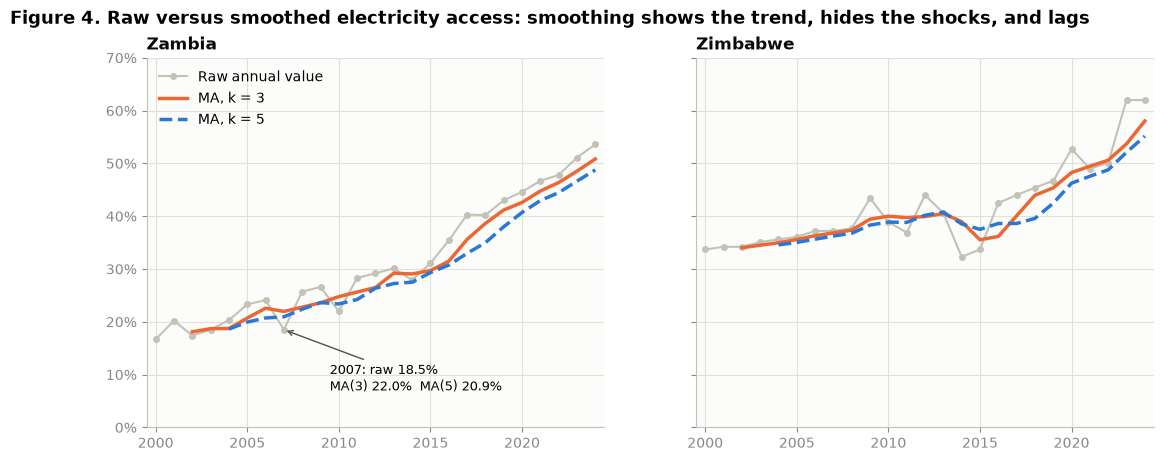

,access,ma3,ma5
year,,,
2006,24.1,22.57,20.72
2007,18.5,21.97,20.94
2008,25.7,22.77,22.38
2022,47.8,46.37,44.46
2023,51.1,48.53,46.64
2024,53.6,50.83,48.76


In [5]:
sm = analysis.smoothed(df, "access", ks=(3, 5))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, iso in zip(axes, ["ZMB", "ZWE"]):
    s = sm[sm["iso3"] == iso]
    ax.plot(s["year"], s["access"], color=style.GREY, lw=1.5, marker="o", ms=4, label="Raw annual value", zorder=2)
    ax.plot(s["year"], s["ma3"], color=style.FOCUS, lw=2.5, label="MA, k = 3", zorder=3)
    ax.plot(s["year"], s["ma5"], color=style.BLUE, lw=2.5, ls="--", label="MA, k = 5", zorder=3)
    ax.set_title(NAMES[iso])
    ax.set_ylim(0, 70)
    ax.set_xlim(YEAR_MIN - 0.5, YEAR_MAX + 0.5)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
axes[0].legend(loc="upper left")
z = sm[sm["iso3"] == "ZMB"].set_index("year")
axes[0].annotate("2007: raw 18.5%\nMA(3) 22.0%  MA(5) 20.9%", (2007, 18.5), xytext=(2009.5, 7),
                 arrowprops=dict(arrowstyle="->", color=style.INK_2), fontsize=9)
fig.suptitle("Figure 4. Raw versus smoothed electricity access: smoothing shows the trend, hides the shocks, and lags",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
style.save(fig, "fig04_raw_vs_smoothed")
plt.show()
z.loc[[2006, 2007, 2008, 2022, 2023, 2024], ["access", "ma3", "ma5"]]

**What smoothing reveals:**
- The underlying path is a slow climb to about 2014, followed by a clearly steeper climb. Zambia's raw
  series shows four one-year falls that make that pattern hard to see.
- Zimbabwe's very noisy series (year-on-year SD 4.4 pp, the highest of the nine) becomes a readable
  trend: flat 2005–2015, then a steady rise.

**What smoothing hides:**
- **Shocks.** Zambia's 2007 value of 18.5% (a 5.6-point drop) is softened to 22.0% by MA(3) and to 20.9%
  by MA(5). The analyst would no longer see that 2007 is suspicious.
- **Timing.** A trailing average lags the data by (k−1)/2 years. In 2024 the MA(5) reads 48.8% while the
  raw value is 53.6%, so smoothing *understates* recent progress precisely when growth accelerates.
- **Data at the start.** The first k−1 years of every series are lost.

Because the anomalies are likely measurement artefacts (see 2.3), smoothing is the right lens for the
trend and the wrong lens for data quality. Both views are needed.

### 2.2 Long-term trend and structural change

For each country: an ordinary least-squares trend (pp per year) and a two-segment (piecewise linear)
model y = a + b·t + c·max(0, t − τ). The breakpoint τ is chosen to minimise the squared error, with at
least five years on each side. "SSE reduction" is how much better the two-segment fit is than a single
straight line.

In [6]:
ts = analysis.temporal_summary(df)
ts_display = ts[["country", "access_2000", "access_2024", "trend_pp_per_year", "trend_r2", "break_year",
                 "slope_before", "slope_after", "break_sse_reduction", "yoy_sd", "n_drops_gt3"]]
ts_display

,country,access_2000,access_2024,trend_pp_per_year,trend_r2,break_year,slope_before,slope_after,break_sse_reduction,yoy_sd,n_drops_gt3
0,Botswana,26.5,80.2,2.34,0.99,2015,2.58,1.83,0.47,2.04,0
1,Tanzania,8.7,52.4,1.79,0.88,2011,0.38,2.91,0.89,2.36,1
2,Zambia,16.7,53.6,1.50,0.92,2014,0.94,2.39,0.65,3.06,2
3,Mozambique,6.1,36.9,1.31,0.98,2007,1.16,1.35,0.05,1.83,0
4,Angola,24.2,55.5,1.19,0.91,2014,1.04,1.42,0.06,3.49,3
5,Namibia,36.5,59.3,0.95,0.98,2011,0.87,1.01,0.06,1.63,0
6,Zimbabwe,33.7,62.0,0.93,0.68,2015,0.24,2.37,0.58,4.35,4
7,South Africa,72.4,90.2,0.59,0.80,2005,1.95,0.40,0.57,1.99,0
8,Malawi,4.8,15.6,0.47,0.82,2006,0.13,0.54,0.10,2.28,1


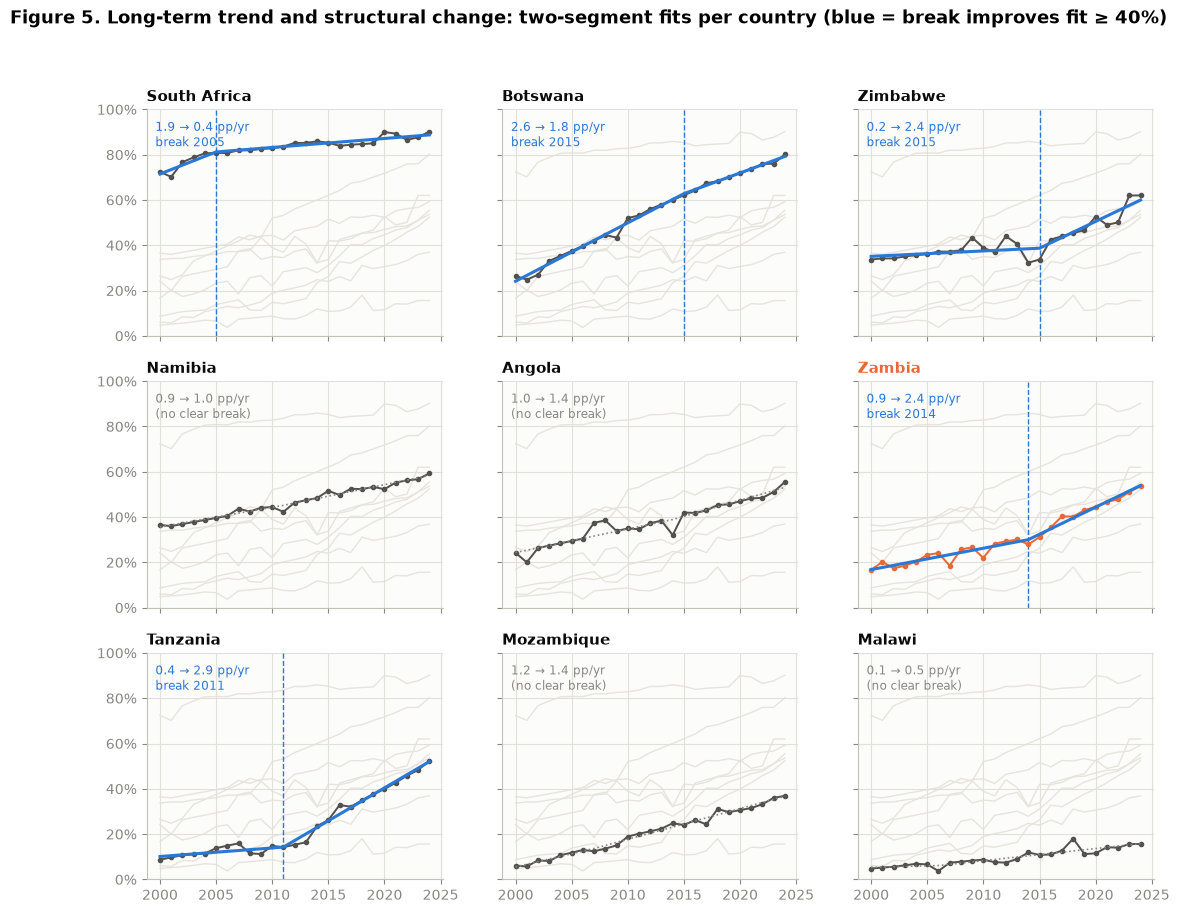

In [7]:
order = ts.sort_values("access_2024", ascending=False)["iso3"].tolist()
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharex=True, sharey=True)
for ax, iso in zip(axes.flat, order):
    d = df[df["iso3"] == iso]
    row = ts.set_index("iso3").loc[iso]
    for other in order:  # grey context: every other country, so each panel keeps the regional frame
        o = df[df["iso3"] == other]
        ax.plot(o["year"], o["access"], color="#e6e4dc", lw=1, zorder=1)
    ax.plot(d["year"], d["access"], color=style.FOCUS if iso == "ZMB" else style.INK_2, lw=1.4, marker="o", ms=3, zorder=3)
    bp = analysis.best_breakpoint(d["year"], d["access"])
    t = d["year"].to_numpy(float)
    X = np.column_stack([np.ones_like(t), t, np.maximum(0, t - bp["year"])])
    coef, *_ = np.linalg.lstsq(X, d["access"].to_numpy(float), rcond=None)
    strong = row["break_sse_reduction"] >= 0.4
    ax.plot(t, X @ coef, color=style.BLUE if strong else style.MUTED, lw=2.2 if strong else 1.2,
            ls="-" if strong else ":", zorder=4)
    if strong:
        ax.axvline(bp["year"], color=style.BLUE, lw=1, ls="--", zorder=2)
    ax.set_title(f"{NAMES[iso]}", fontsize=11, color=style.FOCUS if iso == "ZMB" else style.INK)
    ax.text(0.03, 0.95, f"{row['slope_before']:.1f} → {row['slope_after']:.1f} pp/yr" + (f"\nbreak {bp['year']}" if strong else "\n(no clear break)"),
            transform=ax.transAxes, va="top", fontsize=8.5, color=style.BLUE if strong else style.MUTED)
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
fig.suptitle("Figure 5. Long-term trend and structural change: two-segment fits per country (blue = break improves fit ≥ 40%)",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
style.save(fig, "fig05_trend_breakpoints_small_multiples")
plt.show()

**Reading Figure 5.**
- **Acceleration in the "middle" group.** Tanzania's trend jumps from 0.4 to 2.9 pp/yr around 2011 (the
  two-segment fit removes 89% of the single-line error). Zambia's rises from 0.9 to 2.4 pp/yr around
  2014, and Zimbabwe's from 0.2 to 2.4 pp/yr around 2015.
- **Deceleration near the ceiling.** South Africa slows from 1.9 to 0.4 pp/yr after 2005 as it approaches
  saturation; Botswana slows slightly after 2015.
- **Steady but slow.** Mozambique, Namibia, Angola and Malawi show no meaningful break. They are steady,
  but Malawi's 0.5 pp/yr is far too slow.

The breakpoints describe *when* the pace changed. They cannot say *why*: the data contain no policy or
investment variables (see limitations).

### 2.3 Short-term variation and anomalies

Short-term variation is the year-on-year change. Anomalies are detected without assuming they are
errors. For each year, a straight line is fitted to the neighbouring years (±2, leaving the year itself
out) and used to predict it. A year is flagged when its residual exceeds 3 robust standard deviations.
The robust scale is 1.4826 × the median absolute deviation, pooled over all countries so a volatile
country cannot hide its own outliers.

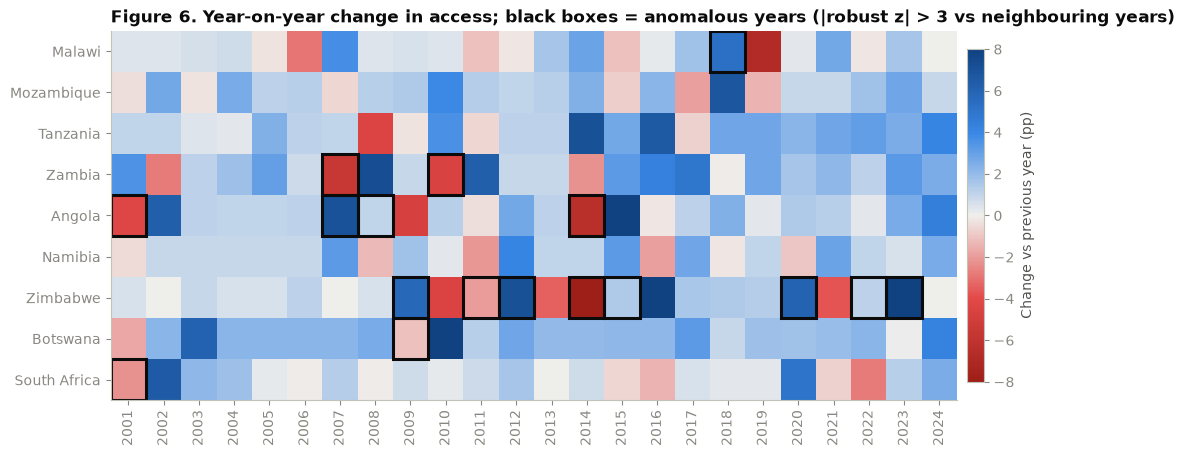

,country,year,access,expected,residual,robust_z
0,Angola,2001,20.0,25.26,-5.26,-3.73
1,Angola,2007,37.5,33.05,4.45,3.16
2,Angola,2008,38.5,34.20,4.30,3.05
3,Angola,2014,32.0,39.88,-7.88,-5.59
4,Botswana,2009,43.4,47.90,-4.50,-3.19
5,Malawi,2018,18.0,11.60,6.40,4.54
6,South Africa,2001,70.2,74.54,-4.34,-3.08
7,Zambia,2007,18.5,24.93,-6.43,-4.56
8,Zambia,2010,22.0,27.45,-5.45,-3.87
9,Zimbabwe,2009,43.4,37.67,5.73,4.06


In [8]:
an = analysis.anomalies(df)
yoy = df.pivot(index="country", columns="year", values="yoy_change").drop(columns=YEAR_MIN)
yoy = yoy.reindex(df[df["year"] == YEAR_MAX].sort_values("access")["country"])
fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(yoy.to_numpy(), cmap=style.DIVERGING, vmin=-8, vmax=8, aspect="auto")
ax.set_xticks(range(yoy.shape[1]), yoy.columns, rotation=90)
ax.set_yticks(range(yoy.shape[0]), yoy.index)
ax.grid(False)
for _, r in an.iterrows():
    i = list(yoy.index).index(r["country"])
    j = list(yoy.columns).index(r["year"])
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=style.INK, lw=2.2))
fig.colorbar(im, ax=ax, shrink=0.9, pad=0.01, label="Change vs previous year (pp)")
ax.set_title("Figure 6. Year-on-year change in access; black boxes = anomalous years (|robust z| > 3 vs neighbouring years)")
style.save(fig, "fig06_short_term_variation_anomalies")
plt.show()
an

**Reading Figure 6.** A box marks a year whose *level* is out of line with its neighbours, so the
matching colour can sit in that year's cell (the jump into the year) or the next (the jump back).
Most cells are light blue: steady small gains. The anomalies (17 country-years)
cluster in a few countries: **Zimbabwe (8)**, Angola (4), Zambia (2007, 2010), and one each in Botswana,
Malawi and South Africa. Most come in down-then-up pairs. Zimbabwe 2014–15 falls 8 points and recovers;
Malawi jumps to 18% in 2018 and returns to 11% in 2019. A real loss of connections for a third of a
country's population in one year, followed by full recovery, is implausible. These pairs are much more
consistent with WDI's modelling: values are interpolated between household surveys and re-estimated
when a new survey arrives. They are therefore flagged, not corrected.

## Task 3: Geospatial analysis

The dataset has country codes (for choropleth joins) and capital-city coordinates (for point symbols).
The analogue of the brief's *disease rate = cases / population × 100,000* is

**access rate** = people with electricity / population × 100, against the **count** of people without electricity.

Comparing raw counts across countries of 2.5 million (Botswana) and 68.6 million (Tanzania) people would
mostly map population size. Rates alone would hide where most people actually lack power. Both maps are
needed, and they answer different questions.

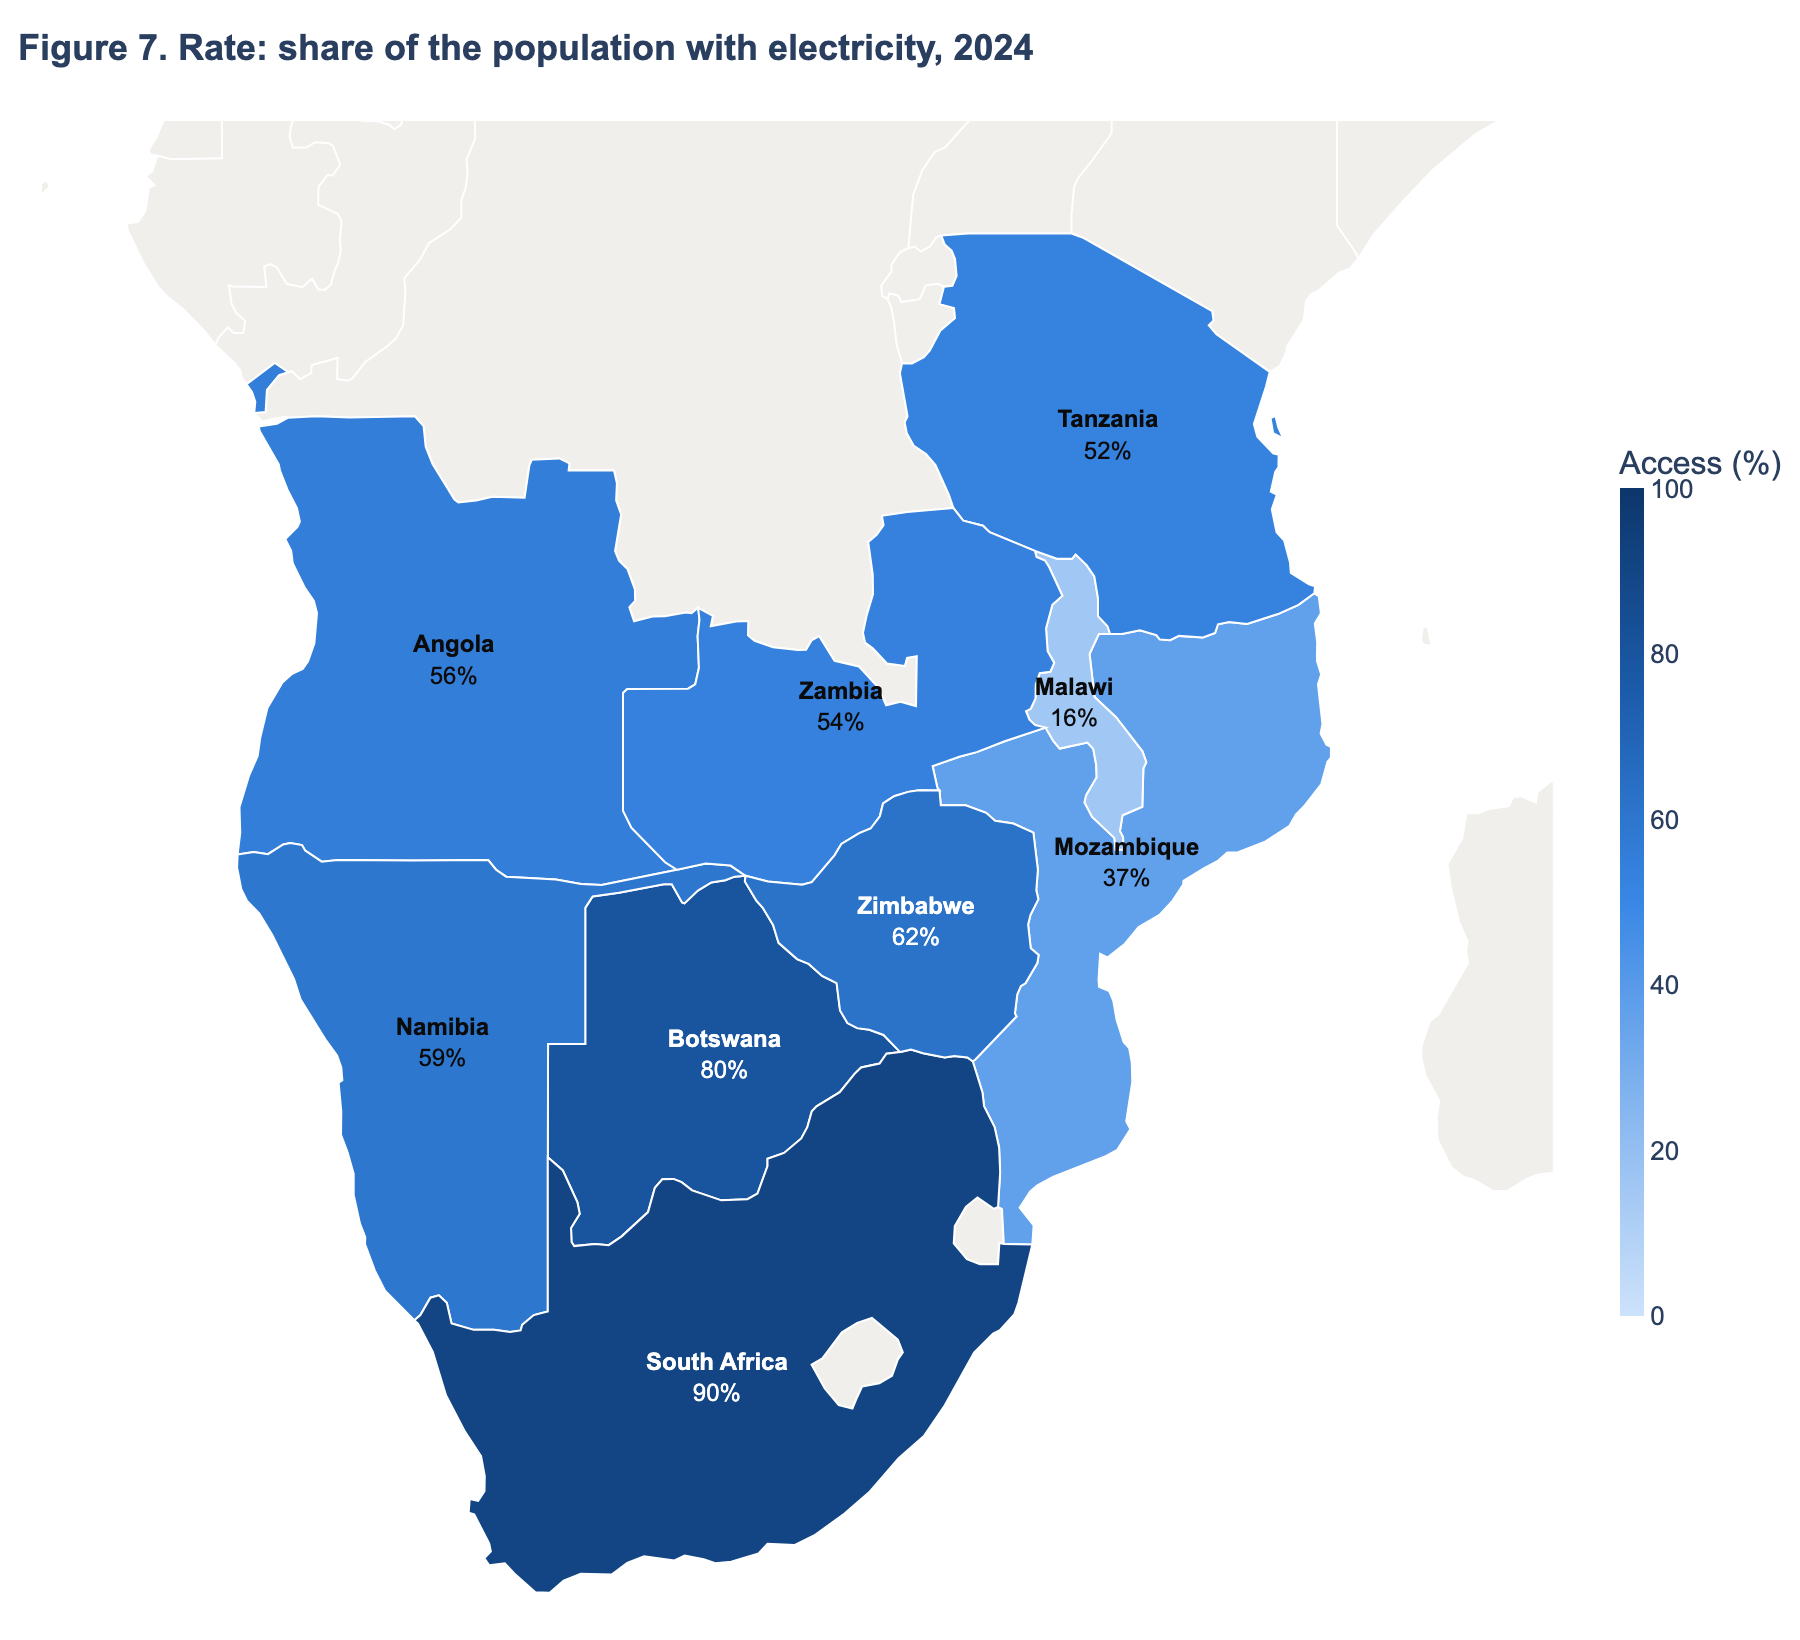

In [9]:
d24 = df[df["year"] == YEAR_MAX].copy()
# Symbols and labels go at approximate country centroids (lat, lon), not at the capitals in the dataset:
# capitals such as Luanda, Maputo and Pretoria sit on coasts/borders and would put a country's symbol
# on its neighbour. Values are rounded centroids, accurate enough for placing a symbol.
CENTROID = {"AGO": (-12.3, 17.5), "BWA": (-22.3, 24.7), "MWI": (-13.4, 34.0), "MOZ": (-17.5, 35.4), "NAM": (-22.0, 17.2),
            "ZAF": (-30.0, 24.5), "TZA": (-6.4, 34.9), "ZMB": (-13.5, 27.8), "ZWE": (-19.0, 29.8)}
d24["clat"] = d24["iso3"].map(lambda i: CENTROID[i][0])
d24["clon"] = d24["iso3"].map(lambda i: CENTROID[i][1])


def africa_geo(fig):
    fig.update_geos(scope="africa", fitbounds="locations", visible=False, showcountries=True, countrycolor="white",
                    showland=True, landcolor="#f0efec", projection_type="mercator")
    fig.update_layout(margin=dict(l=0, r=0, t=60, b=0), paper_bgcolor="white", font=dict(family="Arial", size=13))
    return fig


blues = [[0, "#cde2fb"], [0.25, "#86b6ef"], [0.5, "#3987e5"], [0.75, "#1c5cab"], [1, "#0d366b"]]
fig = go.Figure(go.Choropleth(locations=d24["iso3"], z=d24["access"], colorscale=blues, zmin=0, zmax=100,
                              marker_line_color="white", marker_line_width=1,
                              colorbar=dict(title="Access (%)", thickness=12, len=0.6)))
fig.add_trace(go.Scattergeo(lon=d24["clon"], lat=d24["clat"], mode="text",
                            text=[f"<b>{c}</b><br>{a:.0f}%" for c, a in zip(d24["country"], d24["access"])],
                            textfont=dict(size=12, color=["white" if a > 60 else "#0b0b0b" for a in d24["access"]])))
fig.update_layout(title=dict(text="<b>Figure 7. Rate: share of the population with electricity, 2024</b>", x=0.01))
africa_geo(fig)
fig.write_image(style.FIG_DIR / "fig07_map_access_rate_2024.png", width=900, height=820, scale=2)
display(Image(filename=str(style.FIG_DIR / "fig07_map_access_rate_2024.png"), width=620))

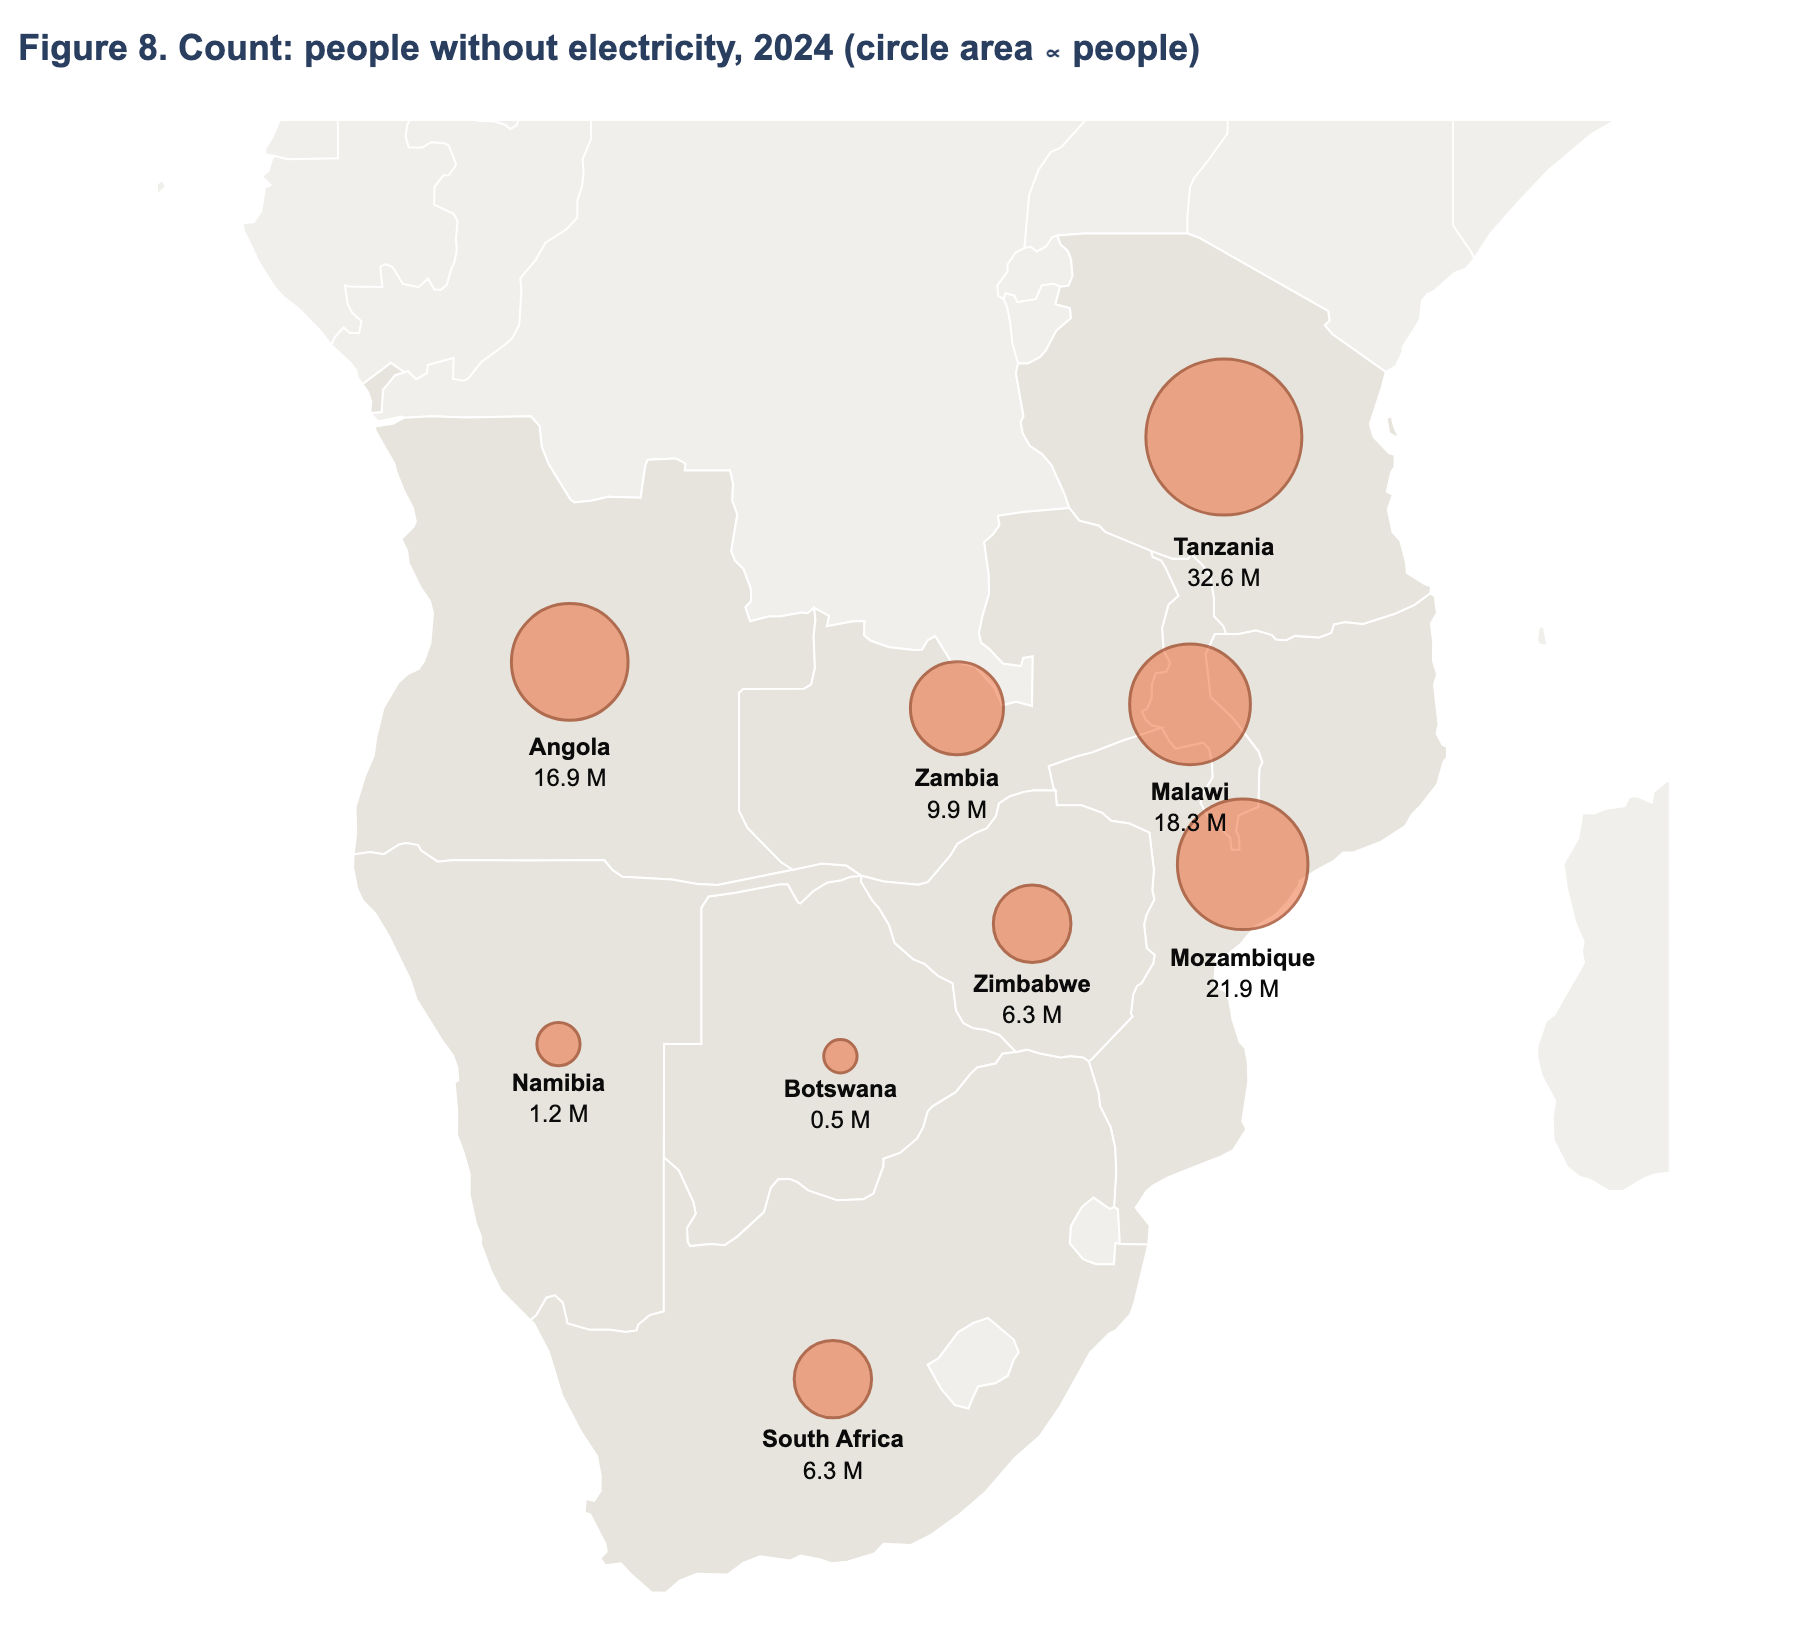

In [10]:
pw = d24["pop_without_m"]
fig = go.Figure(go.Choropleth(locations=d24["iso3"], z=[1] * len(d24), colorscale=[[0, "#e6e4dc"], [1, "#e6e4dc"]],
                              showscale=False, marker_line_color="white", marker_line_width=1, hoverinfo="skip"))
fig.add_trace(go.Scattergeo(lon=d24["clon"], lat=d24["clat"], mode="markers+text",
                            marker=dict(size=8 + 70 * np.sqrt(pw / pw.max()), color="rgba(235,104,52,0.75)",
                                        line=dict(color="#9a3a15", width=1.5), sizemode="diameter"),
                            text=[f"<b>{c}</b><br>{v:.1f} M" for c, v in zip(d24["country"], pw)],
                            textposition="bottom center", textfont=dict(size=12, color="#0b0b0b")))
fig.update_layout(title=dict(text="<b>Figure 8. Count: people without electricity, 2024 (circle area ∝ people)</b>", x=0.01))
africa_geo(fig)
fig.write_image(style.FIG_DIR / "fig08_map_people_without_2024.png", width=900, height=820, scale=2)
display(Image(filename=str(style.FIG_DIR / "fig08_map_people_without_2024.png"), width=620))

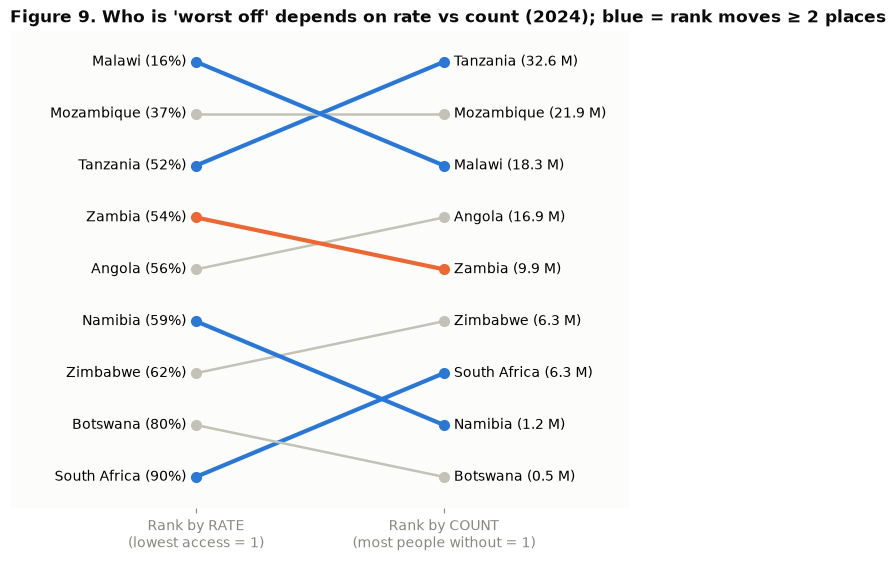

,country,access,pop_without_m,rank_by_rate_deficit,rank_by_count,share_of_region_deficit
0,Tanzania,52.4,32.63,3,1,2.87e-01
1,Mozambique,36.9,21.85,2,2,1.92e-01
2,Malawi,15.6,18.28,1,3,1.61e-01
3,Angola,55.5,16.86,5,4,1.48e-01
4,Zambia,53.6,9.89,4,5,8.69e-02
5,Zimbabwe,62.0,6.32,7,6,5.55e-02
6,South Africa,90.2,6.27,9,7,5.51e-02
7,Namibia,59.3,1.23,6,8,1.08e-02
8,Botswana,80.2,0.50,8,9,4.38e-03


In [11]:
rc = analysis.rates_vs_counts(df, YEAR_MAX)
fig, ax = plt.subplots(figsize=(8, 6.2))
for _, r in rc.iterrows():
    c = style.FOCUS if r["iso3"] == "ZMB" else (style.BLUE if abs(r["rank_by_rate_deficit"] - r["rank_by_count"]) >= 2 else style.GREY)
    ax.plot([0, 1], [r["rank_by_rate_deficit"], r["rank_by_count"]], color=c, lw=3 if c != style.GREY else 1.8, marker="o", ms=7)
    ax.text(-0.04, r["rank_by_rate_deficit"], f"{r['country']} ({r['access']:.0f}%)", ha="right", va="center", fontsize=10)
    ax.text(1.04, r["rank_by_count"], f"{r['country']} ({r['pop_without_m']:.1f} M)", ha="left", va="center", fontsize=10)
ax.set_ylim(9.6, 0.4)
ax.set_xlim(-0.75, 1.75)
ax.set_xticks([0, 1], ["Rank by RATE\n(lowest access = 1)", "Rank by COUNT\n(most people without = 1)"])
ax.set_yticks([])
ax.grid(False)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Figure 9. Who is 'worst off' depends on rate vs count (2024); blue = rank moves ≥ 2 places")
style.save(fig, "fig09_rate_vs_count_ranks")
plt.show()
rc[["country", "access", "pop_without_m", "rank_by_rate_deficit", "rank_by_count", "share_of_region_deficit"]]

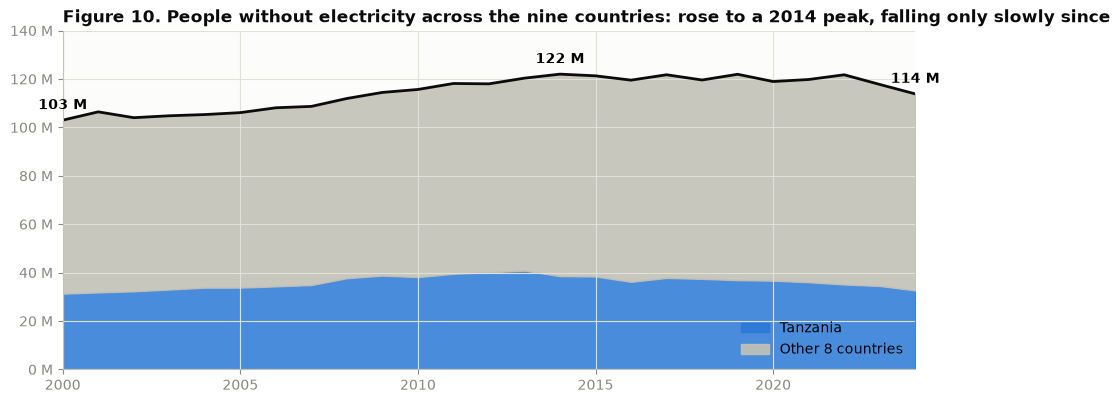

In [12]:
tot = df.groupby("year")["pop_without_m"].sum()
tza = df[df["iso3"] == "TZA"].set_index("year")["pop_without_m"]
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.fill_between(tot.index, 0, tza, color=style.BLUE, alpha=0.85, label="Tanzania")
ax.fill_between(tot.index, tza, tot, color=style.GREY, alpha=0.9, label="Other 8 countries")
ax.plot(tot.index, tot, color=style.INK, lw=2)
peak = tot.idxmax()
for yr in [YEAR_MIN, peak, YEAR_MAX]:
    ax.annotate(f"{tot[yr]:.0f} M", (yr, tot[yr]), xytext=(0, 8), textcoords="offset points", ha="center", fontweight="bold")
ax.set_ylim(0, 140)
ax.set_xlim(YEAR_MIN, YEAR_MAX)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f} M")
ax.legend(loc="lower right")
ax.set_title("Figure 10. People without electricity across the nine countries: rose to a 2014 peak, falling only slowly since")
style.save(fig, "fig10_regional_count_over_time")
plt.show()

**Reading Figures 7–10.**
- **Rate (Fig. 7):** access forms a clear south-to-north gradient. South Africa (90%) and Botswana (80%)
  are dark; an eastern belt of Malawi (16%) and Mozambique (37%) is pale.
- **Count (Fig. 8):** the picture moves north-east. Tanzania alone has **32.6 million people without
  electricity, 29% of the nine-country total**, despite a mid-table rate of 52%. South Africa, at 90%
  access, still has 6.3 million people without power, as many as Zimbabwe at 62%.
- **Ranks (Fig. 9):** the slope chart makes the rank reversal explicit. Malawi is worst by rate but third
  by count. South Africa moves from 9th (best rate) to 7th by count.
- **Over time (Fig. 10):** the regional total of people without electricity *rose* from 103 M (2000) to
  122 M (2014) and is 114 M in 2024. Population growth outpaced connections for half the period.

For targeting investment by *people reached*, the count map is the right one; for judging *policy
performance*, the rate map is. Using one when the question needs the other is the classic
rates-versus-counts error.

## Task 4: Alternative representations

### 4A. "Which countries have the lowest electricity access in 2024, and by how much?" Choropleth (Fig. 7) versus ranked bar chart (Fig. 11)

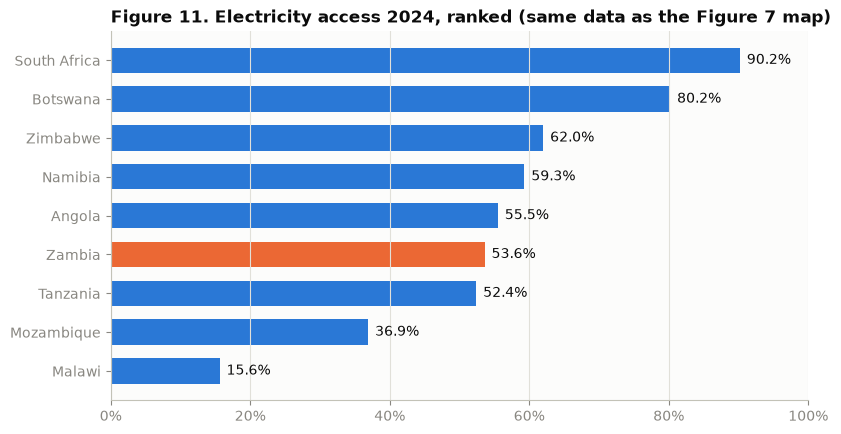

In [13]:
r24 = d24.sort_values("access")
fig, ax = plt.subplots(figsize=(9, 4.8))
cols = [style.FOCUS if i == "ZMB" else style.BLUE for i in r24["iso3"]]
ax.barh(r24["country"], r24["access"], color=cols, height=0.65)
for y, (v, c) in enumerate(zip(r24["access"], r24["country"])):
    ax.text(v + 1, y, f"{v:.1f}%", va="center", fontsize=10, color=style.INK)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.grid(axis="y", visible=False)
ax.set_title("Figure 11. Electricity access 2024, ranked (same data as the Figure 7 map)")
style.save(fig, "fig11_alt_ranked_bar_2024")
plt.show()

**Which representation better supports the task?** For *ranking and magnitude* the **ranked bar chart is better**:
- Length on a common baseline is the most accurately decoded visual channel. Colour lightness, used by
  the choropleth, is among the least accurate (Munzner, 2014).
- The bar chart shows immediately that Zambia (53.6%), Tanzania (52.4%) and Angola (55.5%) are
  effectively tied. On the map the three similar blues cannot be ordered.
- The choropleth also suffers from **area bias**: Angola and Tanzania dominate the map by land area,
  while Malawi, the worst performer, is a thin sliver.

The map wins only for the *spatial* question (is there a geographic pattern?), where it reveals the
south-to-north/east gradient that the bar chart cannot show. Both answer "which country", but only the
bar answers "by how much".

### 4B. "How has each country's access trajectory evolved since 2000?" One multi-line chart (Fig. 12) versus small multiples (Fig. 5)

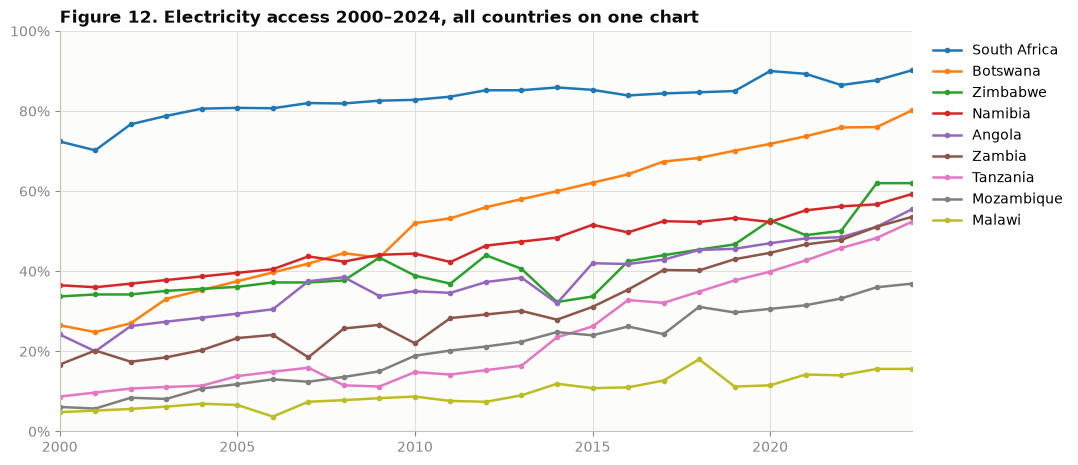

In [14]:
fig, ax = plt.subplots(figsize=(11, 5.2))
for iso in order:
    d = df[df["iso3"] == iso]
    ax.plot(d["year"], d["access"], lw=1.8, marker="o", ms=3, label=NAMES[iso])
ax.set_ylim(0, 100)
ax.set_xlim(YEAR_MIN, YEAR_MAX)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.legend(ncol=1, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("Figure 12. Electricity access 2000–2024, all countries on one chart")
style.save(fig, "fig12_alt_spaghetti")
plt.show()

**Which representation better supports the task?** For *each country's trajectory* (trend shape,
breakpoints, noise), **small multiples (Fig. 5) are better**:
- **The single chart:** nine lines in nine default colours force the reader to match each line to the
  legend. Lines cross repeatedly in the 30–60% band, and several hues (e.g. the greens, the reds) are hard
  to tell apart, especially for colour-blind readers. Zambia's acceleration after 2014 is invisible in the
  tangle.
- **Small multiples:** each panel isolates one country while keeping all others as grey context, on a
  shared 0–100% scale. Shape, breakpoint and anomalies are readable without a legend.

The single chart keeps one advantage: comparing *levels* in a given year across countries is quicker when
all lines share one plot. The dashboard in Assignment 4 combines the two strengths: one chart, with one
highlighted focus country and grey context.

## Task 5: Evidence-based findings

Each finding separates the **observation** (what the data show) from the **interpretation** (what it may
mean, with alternative explanations). The numbers below are computed in this notebook.

In [15]:
m = mats
z_sm = sm[sm["iso3"] == "ZMB"].set_index("year")
row = ts.set_index("iso3")
findings = pd.DataFrame([
    ["F1", "Fig. 1",
     f"Access correlates with log GDP at ρ = {m['between'].loc['access','gdp_pc']:.2f} between countries, {m['within'].loc['access','gdp_pc']:.2f} within countries and {m['changes'].loc['access','gdp_pc']:.2f} for year-to-year changes.",
     "Wealth and electrification are linked through long-run structural differences between countries, not short-run growth; a GDP boom year should not be expected to raise access. Shared time trends inflate within-country correlations."],
    ["F2", "Fig. 1, 3",
     f"The renewables share is negatively associated with access (ρ = {m['pooled'].loc['access','renewables']:.2f} pooled); South Africa has the lowest share ({d21.loc['ZAF','renewables']:.0f}%) and the highest access.",
     "WDI's renewable share includes traditional biomass, so a high share mainly signals reliance on firewood and charcoal in poorer, rural countries, not clean electricity. It should not be read as 'renewables reduce access'."],
    ["F3", "Fig. 2",
     "Urbanisation and access rise together (ρ = 0.88 between countries); the most urban countries have the highest access in both 2000 and 2024.",
     "Density lowers the cost per grid connection, which is consistent with the pattern, but urban measurement bias (surveys reach towns more easily) and wealth could explain part of it."],
    ["F4", "Fig. 5",
     f"Tanzania (break {row.loc['TZA','break_year']}: {row.loc['TZA','slope_before']:.1f} → {row.loc['TZA','slope_after']:.1f} pp/yr), Zambia ({row.loc['ZMB','break_year']}: {row.loc['ZMB','slope_before']:.1f} → {row.loc['ZMB','slope_after']:.1f}) and Zimbabwe ({row.loc['ZWE','break_year']}: {row.loc['ZWE','slope_before']:.1f} → {row.loc['ZWE','slope_after']:.1f}) show structural acceleration; South Africa decelerated after {row.loc['ZAF','break_year']} ({row.loc['ZAF','slope_before']:.1f} → {row.loc['ZAF','slope_after']:.1f}).",
     "The timing coincides with the spread of off-grid solar and rural-electrification programmes in the 2010s, but the data contain no programme variables; methodological changes in the access estimates could also produce a kink. South Africa's slowdown is consistent with approaching saturation."],
    ["F5", "Fig. 4",
     f"Smoothing Zambia's series turns 2007 (raw {z_sm.loc[2007,'access']:.1f}%) into {z_sm.loc[2007,'ma3']:.1f}% (k=3) and {z_sm.loc[2007,'ma5']:.1f}% (k=5), and in 2024 the MA(5) ({z_sm.loc[2024,'ma5']:.1f}%) trails the raw value ({z_sm.loc[2024,'access']:.1f}%) by {z_sm.loc[2024,'access']-z_sm.loc[2024,'ma5']:.1f} points.",
     "Moving averages are useful for trend communication but understate progress during acceleration and hide data-quality problems; reports should show raw and smoothed series together."],
    ["F6", "Fig. 6",
     f"{len(an)} country-years are anomalous (|robust z| > 3); {int((an['country']=='Zimbabwe').sum())} are Zimbabwe, and most occur as drop-then-recovery pairs (e.g. Zimbabwe 2014–15, Malawi 2018–19).",
     "Real one-year losses of 5–8 points of national access followed by recovery are implausible; the pattern is more consistent with survey-based re-estimation. Zimbabwe's economic crises could contribute but cannot be separated from measurement noise here."],
    ["F7", "Fig. 7, 8, 9",
     f"Tanzania holds {rc.set_index('iso3').loc['TZA','share_of_region_deficit']:.0%} of the region's people without electricity ({rc.set_index('iso3').loc['TZA','pop_without_m']:.1f} M) at a mid-table rate; Malawi is worst by rate but 3rd by count; South Africa at 90% still has {rc.set_index('iso3').loc['ZAF','pop_without_m']:.1f} M without power.",
     "Rate and count rankings answer different questions: rates for judging performance, counts for sizing investment by people reached. Choosing one map alone would misdirect either evaluation or targeting."],
    ["F8", "Fig. 10",
     f"The nine-country total of people without electricity rose from {tot.loc[YEAR_MIN]:.0f} M (2000) to a peak of {tot.max():.0f} M ({tot.idxmax()}) and was {tot.loc[YEAR_MAX]:.0f} M in 2024, although every country's access rate rose.",
     "Population growth absorbed connection gains for the first half of the period; universal-access progress measured in percentages overstates progress measured in people."],
], columns=["#", "Evidence", "Observation", "Interpretation"])
findings

,#,Evidence,Observation,Interpretation
0,F1,Fig. 1,Access correlates with log GDP at ρ = 0.97 bet...,Wealth and electrification are linked through ...
1,F2,"Fig. 1, 3",The renewables share is negatively associated ...,WDI's renewable share includes traditional bio...
2,F3,Fig. 2,Urbanisation and access rise together (ρ = 0.8...,"Density lowers the cost per grid connection, w..."
3,F4,Fig. 5,"Tanzania (break 2011: 0.4 → 2.9 pp/yr), Zambia...",The timing coincides with the spread of off-gr...
4,F5,Fig. 4,Smoothing Zambia's series turns 2007 (raw 18.5...,Moving averages are useful for trend communica...
5,F6,Fig. 6,17 country-years are anomalous (|robust z| > 3...,Real one-year losses of 5–8 points of national...
6,F7,"Fig. 7, 8, 9",Tanzania holds 29% of the region's people with...,Rate and count rankings answer different quest...
7,F8,Fig. 10,The nine-country total of people without elect...,Population growth absorbed connection gains fo...


## Methodological limitations

- **Annual national aggregates.** There is no seasonality and no sub-national pattern (province, rural vs
  urban). The maps show *between-country* geography only, so within-country inequality, which is likely
  larger, is invisible (ecological fallacy).
- **Modelled, revised estimates.** WDI access values are interpolated between household surveys and
  re-estimated as new surveys arrive. Anomalies and breakpoints may be measurement artefacts, which is why
  they are flagged, not corrected.
- **Correlation, not causation.** All of Task 1 is associational. Shared time trends inflate
  within-country correlations (Figure 1), and with only 9 countries the between-country correlations rest
  on 9 points. One unusual country can move ρ substantially.
- **Breakpoint search is exploratory.** Choosing the best of ~15 candidate years overfits. The breakpoints
  are descriptive, not tested for significance, and a single break is assumed.
- **Smoothing choices.** Trailing windows lag the data and lose the first k−1 years; the choice of k
  changes what is visible (Figure 4).
- **Map design.** Choropleths carry area bias (large Angola and Tanzania dominate visually). Each count is
  drawn as one circle at an approximate country centroid, which hides where in the country people lack
  power, and the circle-size scale is a design choice.
- **Variables.** GDP is in current US$ (exchange-rate and inflation effects, not real output). Income
  group is a current snapshot. The renewables share includes biomass and stops in 2021.
- **Sample.** Nine purposively selected countries; conclusions should not be generalised to Sub-Saharan Africa.

In [16]:
import json  # export the numbers quoted in the written report (NaN -> null so the file is valid JSON)
import math


def _clean(o):
    if isinstance(o, float) and math.isnan(o):
        return None
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, list):
        return [_clean(v) for v in o]
    return o


numbers = {
    "corr": {k: v.round(3).to_dict() for k, v in mats.items()},
    "temporal": ts.round(3).to_dict(orient="records"),
    "anomalies": an.round(2).to_dict(orient="records"),
    "rates_vs_counts": rc.round(3).to_dict(orient="records"),
    "region_without": tot.round(2).to_dict(),
    "zambia_smoothed": z_sm[["access", "ma3", "ma5"]].round(2).reset_index().to_dict(orient="records"),
    "findings": findings.to_dict(orient="records"),
}
json.dump(_clean(json.loads(json.dumps(numbers, default=float))), open(style.FIG_DIR / "numbers.json", "w"), indent=1, allow_nan=False)
print("figures:", sorted(p.name for p in style.FIG_DIR.glob("*.png")))

figures: ['fig01_correlation_views.png', 'fig02_bubble_wealth_access_urban.png', 'fig03_parallel_coordinates_2021.png', 'fig04_raw_vs_smoothed.png', 'fig05_trend_breakpoints_small_multiples.png', 'fig06_short_term_variation_anomalies.png', 'fig07_map_access_rate_2024.png', 'fig08_map_people_without_2024.png', 'fig09_rate_vs_count_ranks.png', 'fig10_regional_count_over_time.png', 'fig11_alt_ranked_bar_2024.png', 'fig12_alt_spaghetti.png']
